<a href="https://colab.research.google.com/github/AhmedYounis20/ML_Study/blob/main/ML_Supervised_Learning_Techniques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#study Supervised Learning
**classification techniques**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler

In [3]:
cols =["fLength","fWidth","fSize","fConc","fConc1","fAsym","fM3Long","fM3Trans","fAlpha","fDist","class"]
df = pd.read_csv("sample_data/magic04.data",names=cols)
df.head()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,g
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,g


In [4]:
df['class'] = (df['class'] == 'g').astype(int)

In [5]:
df.head()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,1
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,1
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,1
3,23.8172,9.5728,2.3385,0.6147,0.3922,27.2107,-6.4633,-7.1513,10.4490,116.7370,1
4,75.1362,30.9205,3.1611,0.3168,0.1832,-5.5277,28.5525,21.8393,4.6480,356.4620,1


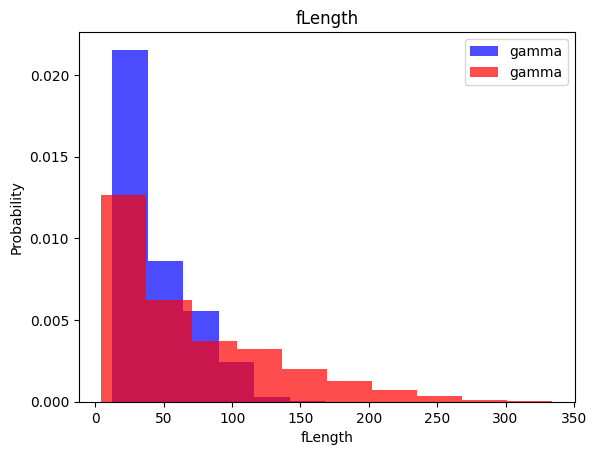

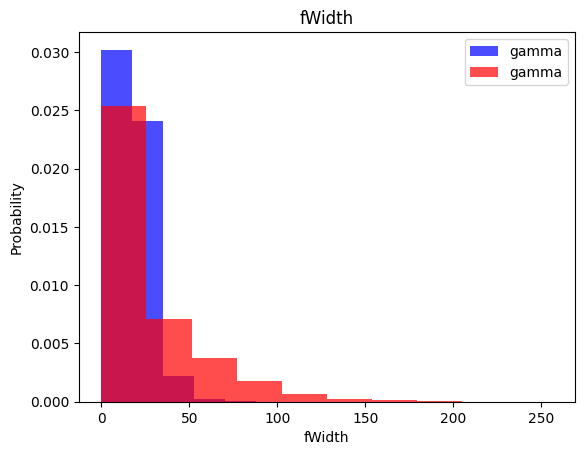

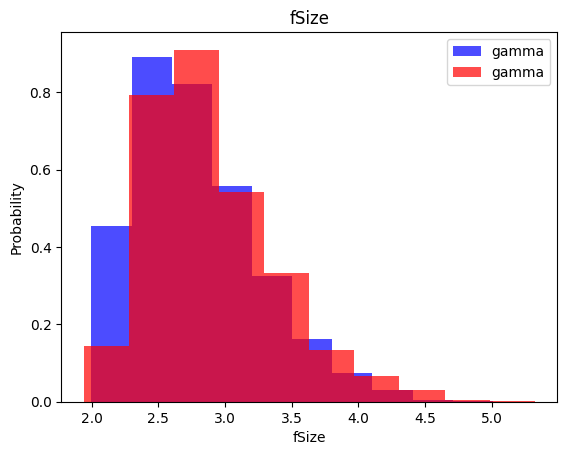

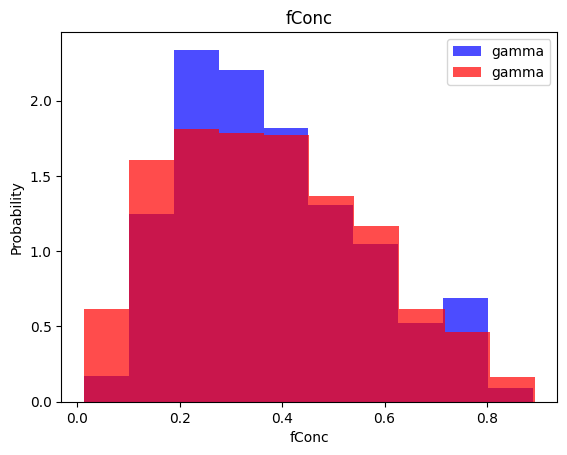

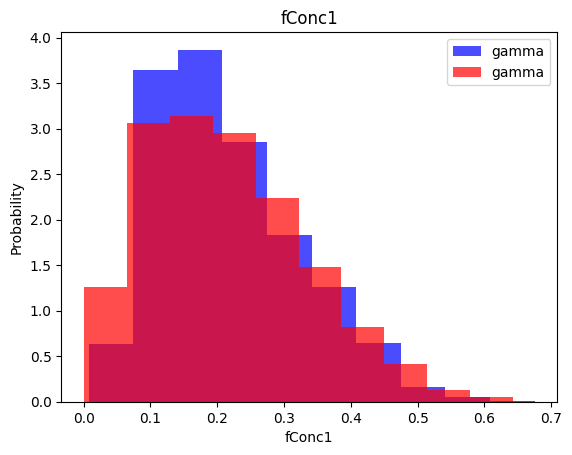

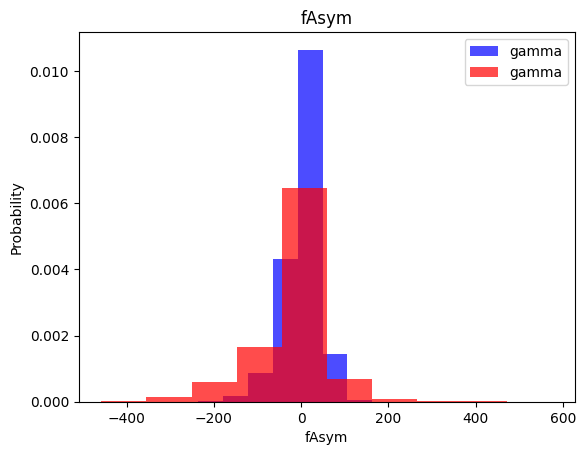

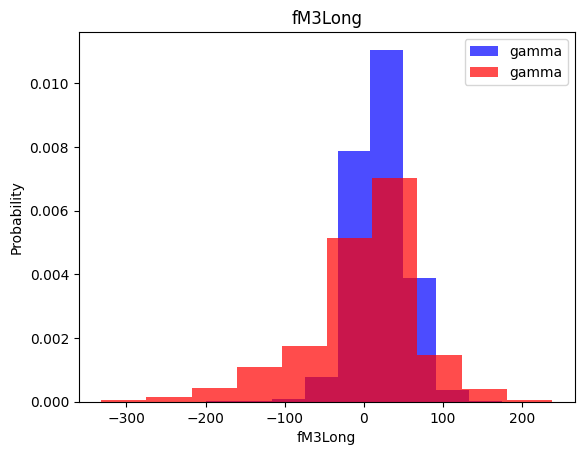

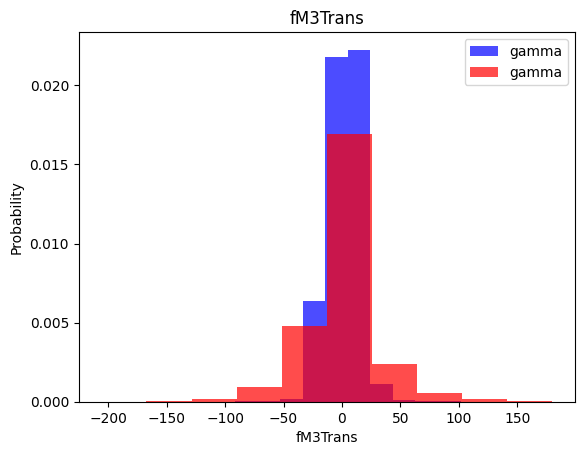

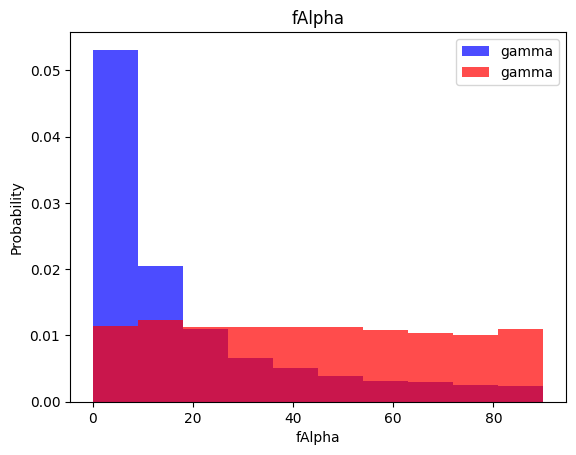

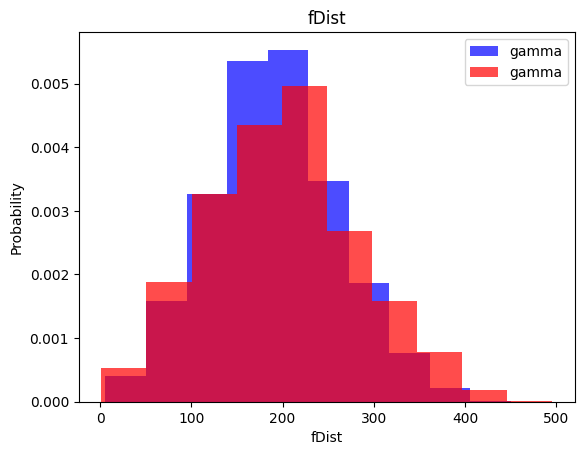

In [6]:
for label in cols[:-1]:
  plt.hist(df[df['class'] ==1 ][label], color='blue', label='gamma', alpha=0.7 , density=True)
  plt.hist(df[df['class'] ==0 ][label],color='red',label='gamma',alpha=0.7,density=True)
  plt.title(label)
  plt.ylabel('Probability')
  plt.xlabel(label)
  plt.legend()
  plt.show()

#Train, Validation, Test datasets

In [7]:
train, valid, test = np.split(df.sample(frac=1),[int(0.6*len(df)),int(0.8*len(df))])


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:54: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [8]:
def scale_dataset(dataframe, oversample=False):
  x= dataframe[dataframe.columns[:-1]].values
  y= dataframe[dataframe.columns[-1]].values

  scaler = StandardScaler()
  x= scaler.fit_transform(x)

  if oversample:
    ros = RandomOverSampler()
    x,y = ros.fit_resample(x,y)
  data = np.hstack((x,np.reshape(y,(-1,1))))
  return data, x, y


In [9]:
train, x_train, y_train = scale_dataset(train,True)
valid, x_valid, y_valid = scale_dataset(valid,False)
test, x_test, y_test = scale_dataset(test,False)

#KNN

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

In [11]:
knn_model = KNeighborsClassifier(n_neighbors=1)
knn_model.fit(x_train,y_train)

KNeighborsClassifier(n_neighbors=1)

In [12]:
y_pred = knn_model.predict(x_test)

In [13]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.74      0.68      0.71      1337
           1       0.84      0.87      0.85      2467

    accuracy                           0.81      3804
   macro avg       0.79      0.78      0.78      3804
weighted avg       0.80      0.81      0.80      3804



#Naive Bayes

In [14]:
from sklearn.naive_bayes import GaussianNB

In [15]:
nb_model = GaussianNB()
nb_model= nb_model.fit(x_train,y_train)

In [16]:
y_pred = nb_model.predict(x_test)

In [17]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.68      0.40      0.50      1337
           1       0.73      0.90      0.81      2467

    accuracy                           0.72      3804
   macro avg       0.70      0.65      0.65      3804
weighted avg       0.71      0.72      0.70      3804



# Logistic Regresssion

In [18]:
from sklearn.linear_model import LogisticRegression

In [19]:
lg_model = LogisticRegression()
lg_model = lg_model.fit(x_train, y_train)

In [20]:
y_pred = lg_model.predict(x_test)

In [21]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.69      0.72      0.71      1337
           1       0.85      0.82      0.83      2467

    accuracy                           0.79      3804
   macro avg       0.77      0.77      0.77      3804
weighted avg       0.79      0.79      0.79      3804



#SVM

In [22]:
from sklearn.svm import SVC

In [23]:
svm_model = SVC()
svm_model = svm_model.fit(x_train, y_train)

In [24]:
y_pred = svm_model.predict(x_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.80      0.80      1337
           1       0.89      0.89      0.89      2467

    accuracy                           0.86      3804
   macro avg       0.84      0.84      0.84      3804
weighted avg       0.86      0.86      0.86      3804



 # Neural Network


In [25]:
import tensorflow as tf

In [26]:
def train_nn_model(x_train, y_train,num_nodes,dropout_prob,lr,batch_size,epochs):

  nn_model = tf.keras.Sequential([
      tf.keras.Input(shape=(10,)),
      tf.keras.layers.Dense(num_nodes,activation='relu'),
      tf.keras.layers.Dropout(dropout_prob),
      tf.keras.layers.Dense(num_nodes,activation ='relu'),
      tf.keras.layers.Dense(1,activation='sigmoid')
  ])

  nn_model.compile(optimizer = tf.keras.optimizers.Adam(lr),loss='binary_crossentropy', metrics=['accuracy'])

  history = nn_model.fit(
      x_train,y_train, epochs = epochs, batch_size=batch_size, validation_split=0.2)
  return nn_model, history

In [27]:
def plot_history(history):
  fig,(ax1, ax2) = plt.subplots(1,2)
  ax1.plot(history.history['accuracy'],label='accuracy')
  ax1.plot(history.history['val_accuracy'],label='val_accuracy')
  ax1.set_xlabel("Epoch")
  ax1.set_ylabel("accuracy")
  ax1.grid(True)

  ax2.plot(history.history['loss'],label='loss')
  ax2.plot(history.history['val_loss'],label='val_loss')
  ax2.set_xlabel("Epoc")
  ax2.set_ylabel("loss")
  ax2.grid(True)
  plt.show()


number of nodes 16, number of dropouts 0, learning rate value 0.01, batch_size 32
Epoch 1/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8199 - loss: 0.4009 - val_accuracy: 0.6452 - val_loss: 0.6437
Epoch 2/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8478 - loss: 0.3490 - val_accuracy: 0.7164 - val_loss: 0.5471
Epoch 3/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8534 - loss: 0.3390 - val_accuracy: 0.7703 - val_loss: 0.4186
Epoch 4/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8588 - loss: 0.3315 - val_accuracy: 0.7386 - val_loss: 0.4833
Epoch 5/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8608 - loss: 0.3291 - val_accuracy: 0.7882 - val_loss: 0.3781
Epoch 6/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8610 - loss: 0.3236 - val_accuracy: 0.7889 - val_loss: 0.3811
Epoch 7/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8633 - loss: 0.3213 - val_accuracy: 0.7690 - val_loss: 0.4440
Epoch 8/100
371

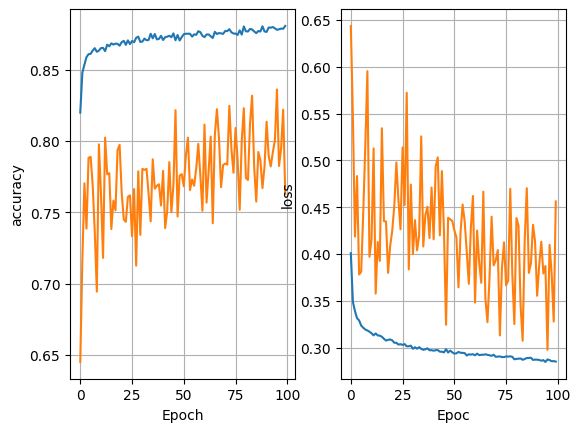

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8736 - loss: 0.3046
number of nodes 16, number of dropouts 0, learning rate value 0.01, batch_size 64
Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8054 - loss: 0.4252 - val_accuracy: 0.6530 - val_loss: 0.6676
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8362 - loss: 0.3746 - val_accuracy: 0.7228 - val_loss: 0.5060
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8497 - loss: 0.3482 - val_accuracy: 0.7801 - val_loss: 0.4109
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8539 - loss: 0.3390 - val_accuracy: 0.7653 - val_loss: 0.4483
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8569 - loss: 0.3320 - val_accuracy: 0.7595 - val_loss: 0.4615
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8606 - loss: 0.3251 - val_accuracy: 0.6992 - val_loss: 0.5304
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.86

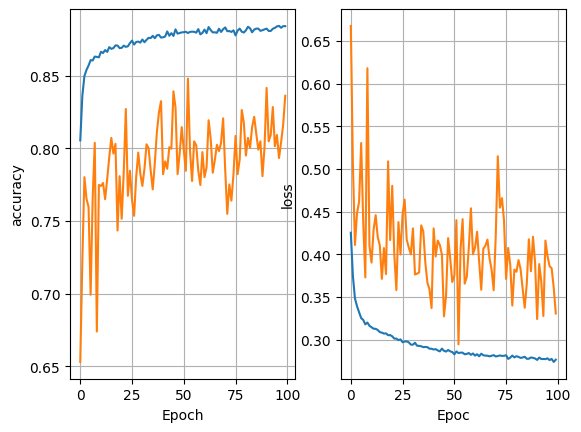

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8612 - loss: 0.3276
number of nodes 16, number of dropouts 0, learning rate value 0.01, batch_size 128
Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7824 - loss: 0.4568 - val_accuracy: 0.7322 - val_loss: 0.5329
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8432 - loss: 0.3637 - val_accuracy: 0.7784 - val_loss: 0.4284
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8520 - loss: 0.3464 - val_accuracy: 0.7160 - val_loss: 0.5704
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8544 - loss: 0.3385 - val_accuracy: 0.7720 - val_loss: 0.4616
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8566 - loss: 0.3345 - val_accuracy: 0.7521 - val_loss: 0.4706
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8579 - loss: 0.3312 - val_accuracy: 0.7616 - val_loss: 0.4551
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8583 - loss: 0.

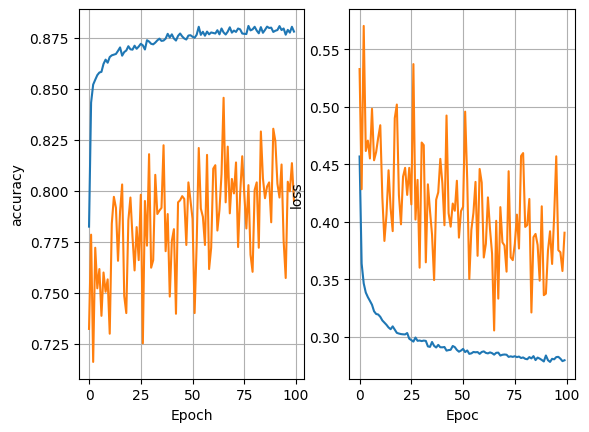

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8654 - loss: 0.3209
number of nodes 16, number of dropouts 0, learning rate value 0.005, batch_size 32
Epoch 1/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8125 - loss: 0.4190 - val_accuracy: 0.7116 - val_loss: 0.5752
Epoch 2/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8507 - loss: 0.3570 - val_accuracy: 0.7143 - val_loss: 0.5775
Epoch 3/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8570 - loss: 0.3446 - val_accuracy: 0.7949 - val_loss: 0.3918
Epoch 4/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8593 - loss: 0.3362 - val_accuracy: 0.7939 - val_loss: 0.4030
Epoch 5/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8590 - loss: 0.3327 - val_accuracy: 0.7676 - val_loss: 0.4303
Epoch 6/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8620 - loss: 0.3265 - val_accuracy: 0.7410 - val_loss: 0.4752
Epoch 7/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8

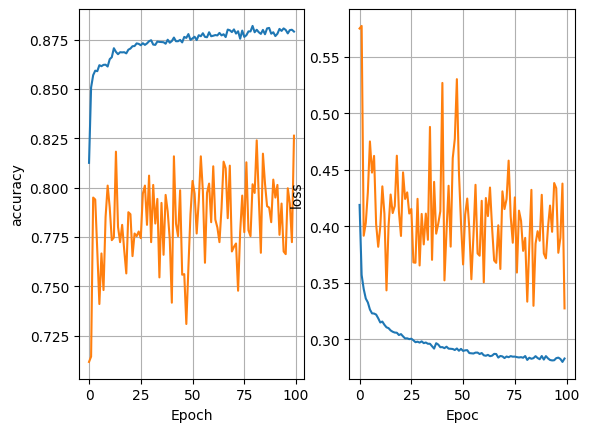

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8667 - loss: 0.3269
number of nodes 16, number of dropouts 0, learning rate value 0.005, batch_size 64
Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7768 - loss: 0.4587 - val_accuracy: 0.7238 - val_loss: 0.5414
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8471 - loss: 0.3623 - val_accuracy: 0.7639 - val_loss: 0.4691
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8539 - loss: 0.3457 - val_accuracy: 0.8145 - val_loss: 0.3539
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8561 - loss: 0.3362 - val_accuracy: 0.7481 - val_loss: 0.4721
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8595 - loss: 0.3310 - val_accuracy: 0.7218 - val_loss: 0.5146
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8604 - loss: 0.3270 - val_accuracy: 0.7457 - val_loss: 0.4769
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8

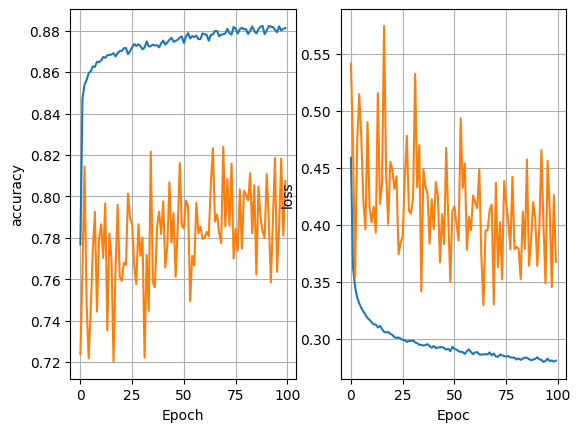

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8688 - loss: 0.3171
number of nodes 16, number of dropouts 0, learning rate value 0.005, batch_size 128
Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7560 - loss: 0.4932 - val_accuracy: 0.6496 - val_loss: 0.5667
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8256 - loss: 0.3897 - val_accuracy: 0.7228 - val_loss: 0.5135
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8438 - loss: 0.3575 - val_accuracy: 0.7494 - val_loss: 0.4753
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8534 - loss: 0.3447 - val_accuracy: 0.7514 - val_loss: 0.4765
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8544 - loss: 0.3364 - val_accuracy: 0.7373 - val_loss: 0.4975
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8560 - loss: 0.3311 - val_accuracy: 0.7639 - val_loss: 0.4483
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8599 - loss: 0

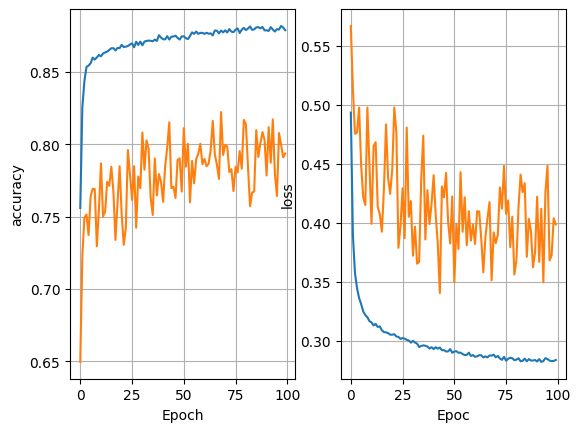

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8701 - loss: 0.3152
number of nodes 16, number of dropouts 0, learning rate value 0.001, batch_size 32
Epoch 1/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7786 - loss: 0.4911 - val_accuracy: 0.6229 - val_loss: 0.6237
Epoch 2/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8203 - loss: 0.3975 - val_accuracy: 0.7224 - val_loss: 0.4935
Epoch 3/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8308 - loss: 0.3811 - val_accuracy: 0.7083 - val_loss: 0.5424
Epoch 4/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8397 - loss: 0.3698 - val_accuracy: 0.7413 - val_loss: 0.4975
Epoch 5/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8424 - loss: 0.3614 - val_accuracy: 0.7373 - val_loss: 0.5055
Epoch 6/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8485 - loss: 0.3545 - val_accuracy: 0.7309 - val_loss: 0.5119
Epoch 7/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8

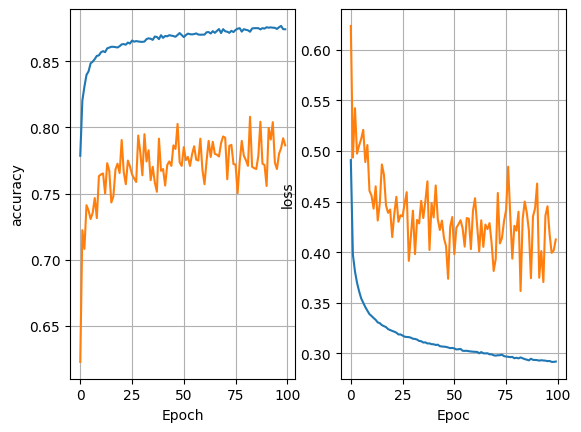

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8762 - loss: 0.3076
number of nodes 16, number of dropouts 0, learning rate value 0.001, batch_size 64
Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7220 - loss: 0.5436 - val_accuracy: 0.6108 - val_loss: 0.6598
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8025 - loss: 0.4265 - val_accuracy: 0.6573 - val_loss: 0.6150
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8182 - loss: 0.4034 - val_accuracy: 0.6776 - val_loss: 0.5876
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8292 - loss: 0.3890 - val_accuracy: 0.7245 - val_loss: 0.5259
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8384 - loss: 0.3793 - val_accuracy: 0.7187 - val_loss: 0.5327
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8415 - loss: 0.3716 - val_accuracy: 0.7379 - val_loss: 0.5062
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8

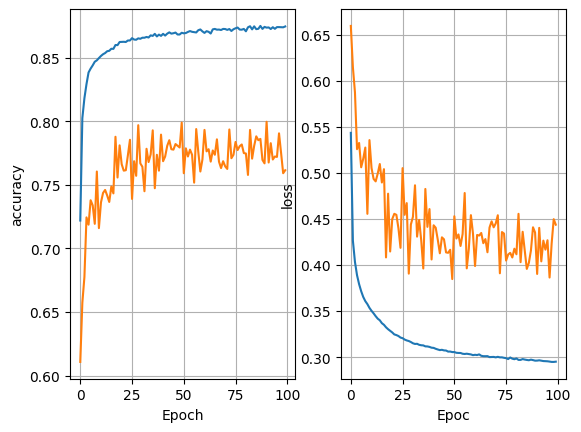

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8767 - loss: 0.3019
number of nodes 16, number of dropouts 0, learning rate value 0.001, batch_size 128
Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6818 - loss: 0.6103 - val_accuracy: 0.5231 - val_loss: 0.6604
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7813 - loss: 0.4692 - val_accuracy: 0.6185 - val_loss: 0.6246
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8050 - loss: 0.4225 - val_accuracy: 0.6435 - val_loss: 0.5926
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8180 - loss: 0.4044 - val_accuracy: 0.6587 - val_loss: 0.5914
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8231 - loss: 0.3933 - val_accuracy: 0.6840 - val_loss: 0.5532
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8308 - loss: 0.3836 - val_accuracy: 0.7143 - val_loss: 0.5095
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8335 - loss: 0

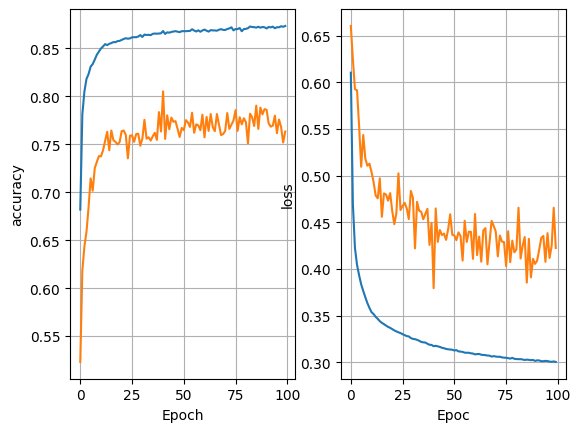

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8722 - loss: 0.3016
number of nodes 16, number of dropouts 0.2, learning rate value 0.01, batch_size 32
Epoch 1/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7948 - loss: 0.4468 - val_accuracy: 0.6759 - val_loss: 0.5704
Epoch 2/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8249 - loss: 0.3933 - val_accuracy: 0.7130 - val_loss: 0.5462
Epoch 3/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8405 - loss: 0.3736 - val_accuracy: 0.7275 - val_loss: 0.5063
Epoch 4/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8413 - loss: 0.3672 - val_accuracy: 0.7862 - val_loss: 0.4143
Epoch 5/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8452 - loss: 0.3608 - val_accuracy: 0.7120 - val_loss: 0.5295
Epoch 6/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8447 - loss: 0.3593 - val_accuracy: 0.7329 - val_loss: 0.4851
Epoch 7/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.

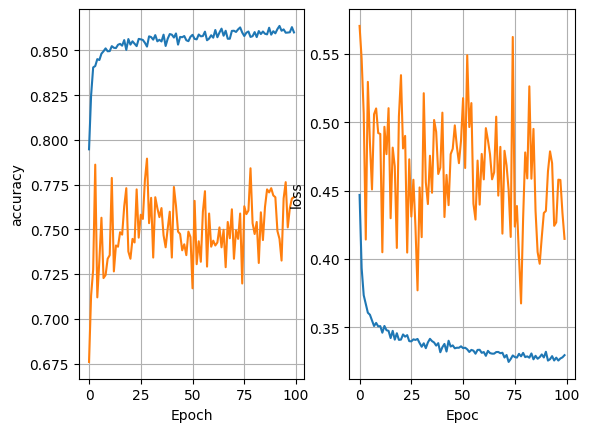

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8715 - loss: 0.3040
number of nodes 16, number of dropouts 0.2, learning rate value 0.01, batch_size 64
Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7893 - loss: 0.4561 - val_accuracy: 0.6243 - val_loss: 0.6835
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8282 - loss: 0.3968 - val_accuracy: 0.7147 - val_loss: 0.5186
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8329 - loss: 0.3794 - val_accuracy: 0.7528 - val_loss: 0.4666
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8409 - loss: 0.3646 - val_accuracy: 0.7649 - val_loss: 0.4244
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8451 - loss: 0.3602 - val_accuracy: 0.7167 - val_loss: 0.5231
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8466 - loss: 0.3558 - val_accuracy: 0.7180 - val_loss: 0.4974
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.

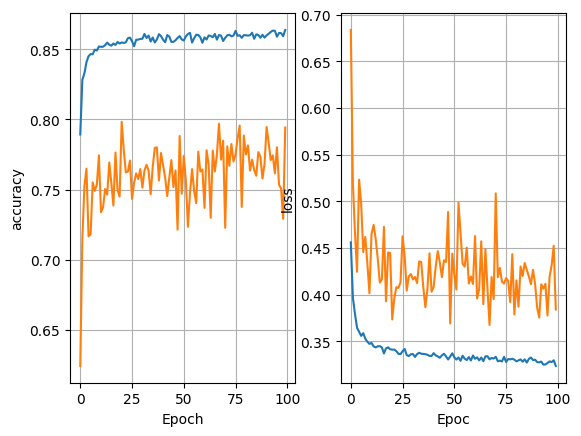

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8764 - loss: 0.3082
number of nodes 16, number of dropouts 0.2, learning rate value 0.01, batch_size 128
Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7765 - loss: 0.4773 - val_accuracy: 0.6907 - val_loss: 0.5545
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8196 - loss: 0.3980 - val_accuracy: 0.7352 - val_loss: 0.4931
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8330 - loss: 0.3823 - val_accuracy: 0.7757 - val_loss: 0.4290
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8403 - loss: 0.3672 - val_accuracy: 0.7383 - val_loss: 0.4743
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8417 - loss: 0.3653 - val_accuracy: 0.7717 - val_loss: 0.4231
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8466 - loss: 0.3569 - val_accuracy: 0.7396 - val_loss: 0.4881
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8502 - loss: 

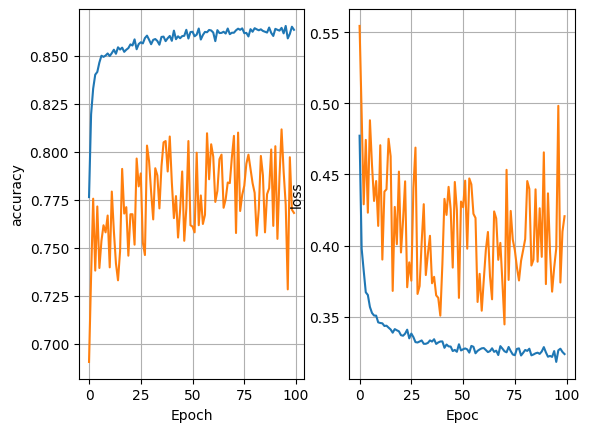

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8804 - loss: 0.3045
number of nodes 16, number of dropouts 0.2, learning rate value 0.005, batch_size 32
Epoch 1/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7913 - loss: 0.4475 - val_accuracy: 0.7390 - val_loss: 0.4866
Epoch 2/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8248 - loss: 0.3956 - val_accuracy: 0.7548 - val_loss: 0.4387
Epoch 3/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8381 - loss: 0.3742 - val_accuracy: 0.7322 - val_loss: 0.5011
Epoch 4/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8372 - loss: 0.3679 - val_accuracy: 0.7939 - val_loss: 0.3851
Epoch 5/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8446 - loss: 0.3612 - val_accuracy: 0.7454 - val_loss: 0.4850
Epoch 6/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8427 - loss: 0.3616 - val_accuracy: 0.7808 - val_loss: 0.4202
Epoch 7/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0

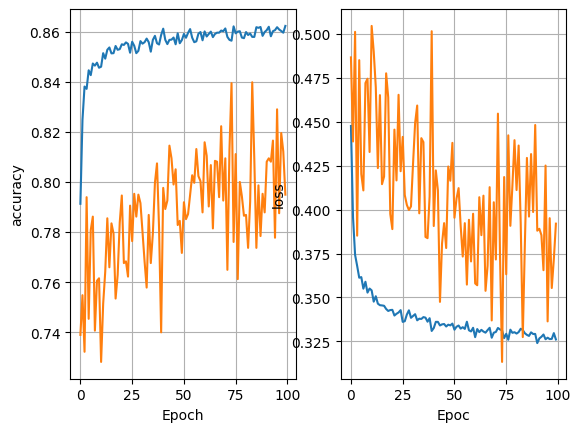

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8741 - loss: 0.3063
number of nodes 16, number of dropouts 0.2, learning rate value 0.005, batch_size 64
Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7769 - loss: 0.4670 - val_accuracy: 0.6631 - val_loss: 0.6036
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8181 - loss: 0.4073 - val_accuracy: 0.7629 - val_loss: 0.4327
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8319 - loss: 0.3870 - val_accuracy: 0.7019 - val_loss: 0.5526
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8399 - loss: 0.3728 - val_accuracy: 0.6954 - val_loss: 0.5947
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8410 - loss: 0.3636 - val_accuracy: 0.7194 - val_loss: 0.5055
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8444 - loss: 0.3615 - val_accuracy: 0.7295 - val_loss: 0.4966
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0

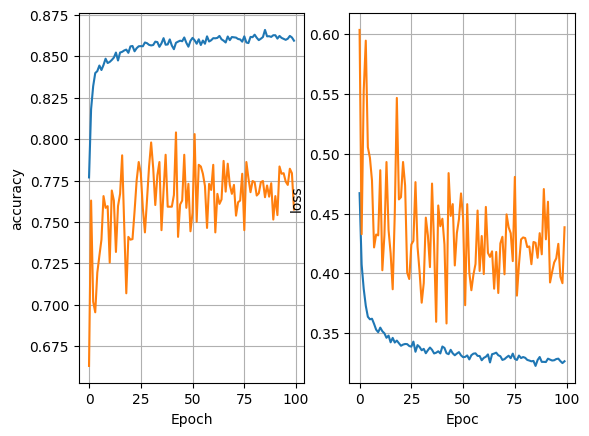

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8788 - loss: 0.3045
number of nodes 16, number of dropouts 0.2, learning rate value 0.005, batch_size 128
Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7668 - loss: 0.4984 - val_accuracy: 0.6742 - val_loss: 0.5666
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8080 - loss: 0.4226 - val_accuracy: 0.6853 - val_loss: 0.5595
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8254 - loss: 0.4035 - val_accuracy: 0.7460 - val_loss: 0.5025
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8328 - loss: 0.3844 - val_accuracy: 0.7481 - val_loss: 0.4894
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8371 - loss: 0.3769 - val_accuracy: 0.7474 - val_loss: 0.4941
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8396 - loss: 0.3695 - val_accuracy: 0.7363 - val_loss: 0.4984
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8427 - loss:

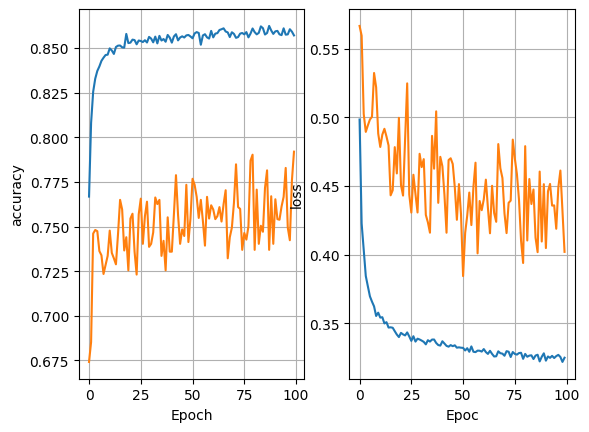

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8696 - loss: 0.3067
number of nodes 16, number of dropouts 0.2, learning rate value 0.001, batch_size 32
Epoch 1/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7209 - loss: 0.5466 - val_accuracy: 0.5987 - val_loss: 0.6670
Epoch 2/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7899 - loss: 0.4491 - val_accuracy: 0.6138 - val_loss: 0.6407
Epoch 3/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8020 - loss: 0.4342 - val_accuracy: 0.6226 - val_loss: 0.6362
Epoch 4/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8109 - loss: 0.4219 - val_accuracy: 0.6880 - val_loss: 0.5757
Epoch 5/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8167 - loss: 0.4111 - val_accuracy: 0.6901 - val_loss: 0.5635
Epoch 6/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8214 - loss: 0.4044 - val_accuracy: 0.7174 - val_loss: 0.5437
Epoch 7/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0

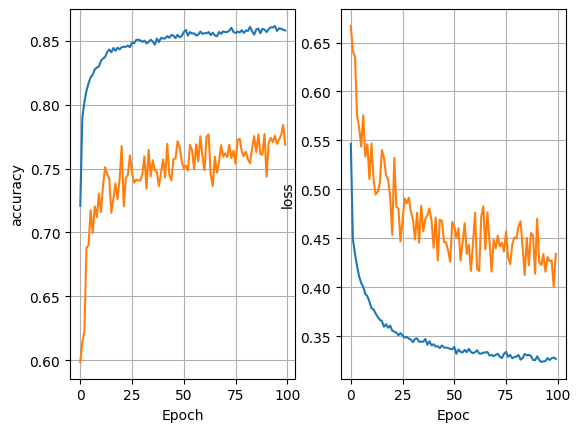

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8759 - loss: 0.3019
number of nodes 16, number of dropouts 0.2, learning rate value 0.001, batch_size 64
Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7236 - loss: 0.5609 - val_accuracy: 0.5528 - val_loss: 0.7002
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7870 - loss: 0.4557 - val_accuracy: 0.6105 - val_loss: 0.6433
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8012 - loss: 0.4335 - val_accuracy: 0.6644 - val_loss: 0.5947
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8104 - loss: 0.4187 - val_accuracy: 0.7039 - val_loss: 0.5400
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8126 - loss: 0.4143 - val_accuracy: 0.6813 - val_loss: 0.5743
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8197 - loss: 0.4038 - val_accuracy: 0.6965 - val_loss: 0.5572
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0

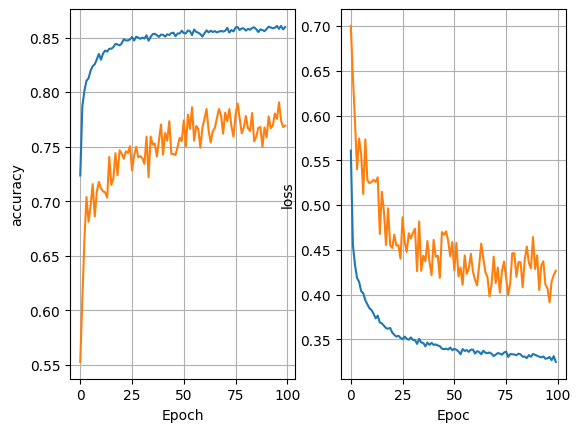

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8780 - loss: 0.2989
number of nodes 16, number of dropouts 0.2, learning rate value 0.001, batch_size 128
Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6922 - loss: 0.5886 - val_accuracy: 0.5447 - val_loss: 0.6896
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7782 - loss: 0.4848 - val_accuracy: 0.5949 - val_loss: 0.6797
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7917 - loss: 0.4555 - val_accuracy: 0.6246 - val_loss: 0.6374
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8022 - loss: 0.4333 - val_accuracy: 0.6320 - val_loss: 0.6432
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8082 - loss: 0.4235 - val_accuracy: 0.6695 - val_loss: 0.5886
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8132 - loss: 0.4175 - val_accuracy: 0.6573 - val_loss: 0.6137
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8148 - loss:

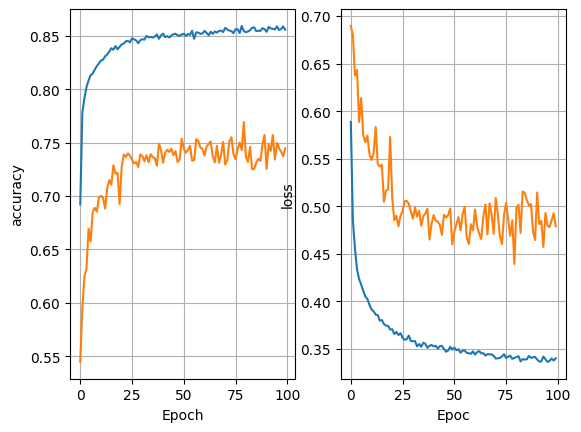

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8791 - loss: 0.3078
number of nodes 32, number of dropouts 0, learning rate value 0.01, batch_size 32
Epoch 1/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8273 - loss: 0.3919 - val_accuracy: 0.7555 - val_loss: 0.4736
Epoch 2/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8501 - loss: 0.3498 - val_accuracy: 0.7980 - val_loss: 0.3768
Epoch 3/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8533 - loss: 0.3384 - val_accuracy: 0.7470 - val_loss: 0.4830
Epoch 4/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8590 - loss: 0.3266 - val_accuracy: 0.7740 - val_loss: 0.4126
Epoch 5/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8615 - loss: 0.3236 - val_accuracy: 0.7673 - val_loss: 0.4455
Epoch 6/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8646 - loss: 0.3182 - val_accuracy: 0.7656 - val_loss: 0.4237
Epoch 7/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.86

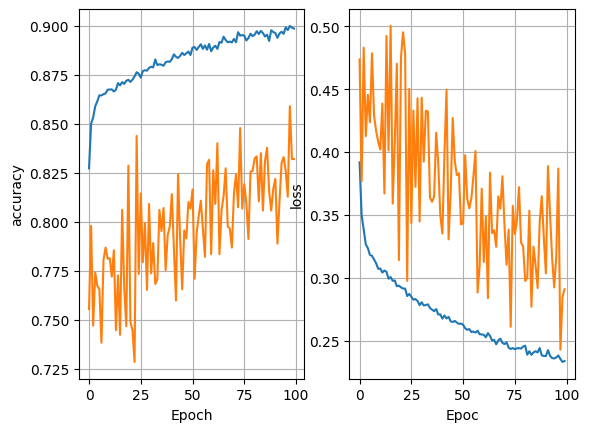

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8638 - loss: 0.3764
number of nodes 32, number of dropouts 0, learning rate value 0.01, batch_size 64
Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8272 - loss: 0.3947 - val_accuracy: 0.6988 - val_loss: 0.6036
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8522 - loss: 0.3455 - val_accuracy: 0.7477 - val_loss: 0.4926
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8558 - loss: 0.3360 - val_accuracy: 0.7325 - val_loss: 0.5095
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8593 - loss: 0.3263 - val_accuracy: 0.7777 - val_loss: 0.4244
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8615 - loss: 0.3219 - val_accuracy: 0.7781 - val_loss: 0.4088
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8633 - loss: 0.3172 - val_accuracy: 0.7373 - val_loss: 0.4876
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.86

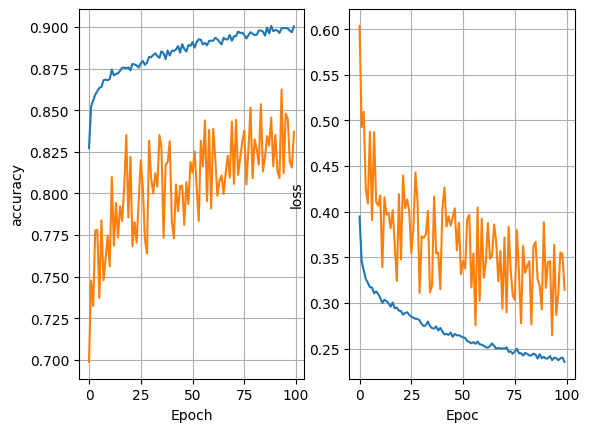

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8586 - loss: 0.4030
number of nodes 32, number of dropouts 0, learning rate value 0.01, batch_size 128
Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8143 - loss: 0.4103 - val_accuracy: 0.7346 - val_loss: 0.5233
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8495 - loss: 0.3534 - val_accuracy: 0.7467 - val_loss: 0.5011
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8553 - loss: 0.3384 - val_accuracy: 0.7450 - val_loss: 0.5128
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8582 - loss: 0.3306 - val_accuracy: 0.8020 - val_loss: 0.3780
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8599 - loss: 0.3261 - val_accuracy: 0.7400 - val_loss: 0.4713
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8622 - loss: 0.3213 - val_accuracy: 0.7261 - val_loss: 0.5156
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8672 - loss: 0.

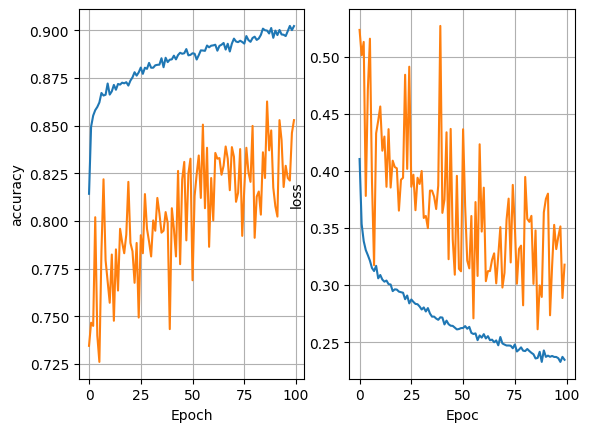

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8651 - loss: 0.3775
number of nodes 32, number of dropouts 0, learning rate value 0.005, batch_size 32
Epoch 1/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8192 - loss: 0.4030 - val_accuracy: 0.7379 - val_loss: 0.5036
Epoch 2/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8507 - loss: 0.3488 - val_accuracy: 0.7066 - val_loss: 0.5553
Epoch 3/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8570 - loss: 0.3370 - val_accuracy: 0.7585 - val_loss: 0.4734
Epoch 4/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8620 - loss: 0.3264 - val_accuracy: 0.7174 - val_loss: 0.5190
Epoch 5/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8615 - loss: 0.3236 - val_accuracy: 0.7278 - val_loss: 0.5230
Epoch 6/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8639 - loss: 0.3179 - val_accuracy: 0.7494 - val_loss: 0.4671
Epoch 7/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8

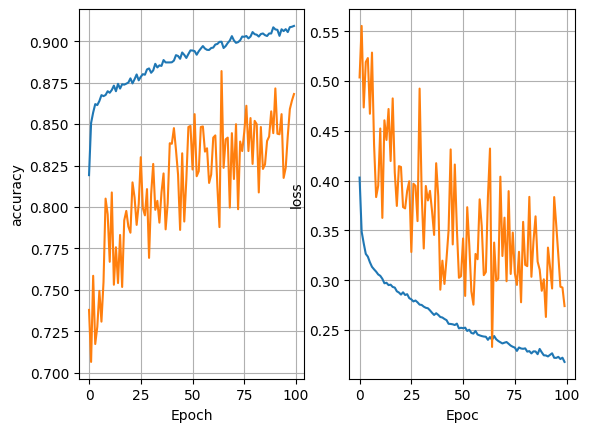

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8546 - loss: 0.3879
number of nodes 32, number of dropouts 0, learning rate value 0.005, batch_size 64
Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8154 - loss: 0.4184 - val_accuracy: 0.7126 - val_loss: 0.5246
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8465 - loss: 0.3567 - val_accuracy: 0.7234 - val_loss: 0.5440
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8534 - loss: 0.3423 - val_accuracy: 0.7535 - val_loss: 0.4851
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8598 - loss: 0.3284 - val_accuracy: 0.7454 - val_loss: 0.4613
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8586 - loss: 0.3247 - val_accuracy: 0.7629 - val_loss: 0.4639
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8651 - loss: 0.3196 - val_accuracy: 0.8287 - val_loss: 0.3216
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8

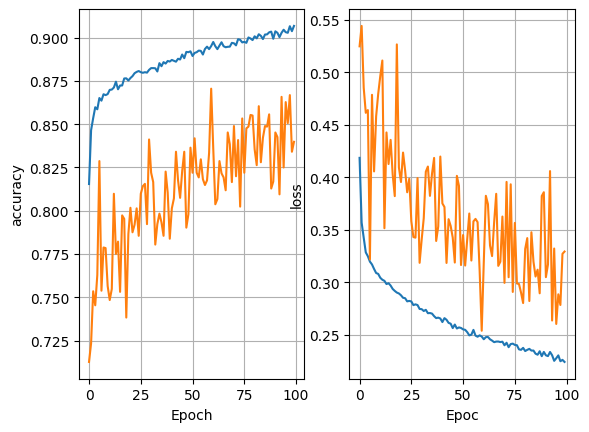

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8601 - loss: 0.3687
number of nodes 32, number of dropouts 0, learning rate value 0.005, batch_size 128
Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.7969 - loss: 0.4440 - val_accuracy: 0.6988 - val_loss: 0.5659
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8474 - loss: 0.3574 - val_accuracy: 0.7049 - val_loss: 0.5715
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8554 - loss: 0.3419 - val_accuracy: 0.7514 - val_loss: 0.4814
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8577 - loss: 0.3338 - val_accuracy: 0.7180 - val_loss: 0.5468
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8587 - loss: 0.3308 - val_accuracy: 0.7889 - val_loss: 0.3968
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8634 - loss: 0.3236 - val_accuracy: 0.7143 - val_loss: 0.5498
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8627 - loss: 0

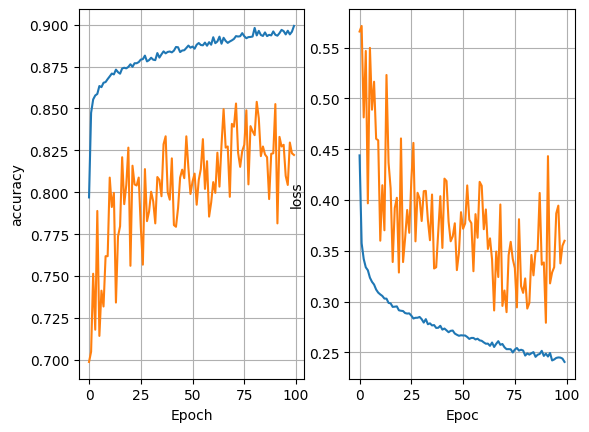

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8696 - loss: 0.3397
number of nodes 32, number of dropouts 0, learning rate value 0.001, batch_size 32
Epoch 1/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7890 - loss: 0.4544 - val_accuracy: 0.6880 - val_loss: 0.5603
Epoch 2/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8365 - loss: 0.3726 - val_accuracy: 0.7383 - val_loss: 0.4884
Epoch 3/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8521 - loss: 0.3515 - val_accuracy: 0.7504 - val_loss: 0.4912
Epoch 4/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8561 - loss: 0.3407 - val_accuracy: 0.7086 - val_loss: 0.5682
Epoch 5/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8569 - loss: 0.3353 - val_accuracy: 0.7352 - val_loss: 0.5085
Epoch 6/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8583 - loss: 0.3296 - val_accuracy: 0.7811 - val_loss: 0.4096
Epoch 7/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8

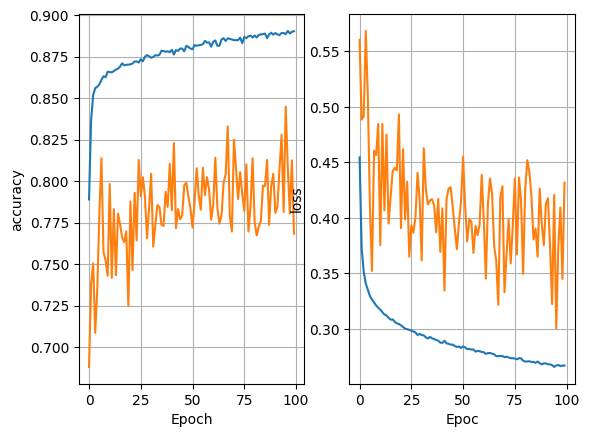

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8759 - loss: 0.3062
number of nodes 32, number of dropouts 0, learning rate value 0.001, batch_size 64
Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7742 - loss: 0.4816 - val_accuracy: 0.6280 - val_loss: 0.6133
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8180 - loss: 0.3974 - val_accuracy: 0.7106 - val_loss: 0.5157
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8350 - loss: 0.3768 - val_accuracy: 0.7437 - val_loss: 0.4901
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8440 - loss: 0.3638 - val_accuracy: 0.7207 - val_loss: 0.5279
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8462 - loss: 0.3553 - val_accuracy: 0.7649 - val_loss: 0.4563
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8527 - loss: 0.3503 - val_accuracy: 0.7369 - val_loss: 0.5085
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8

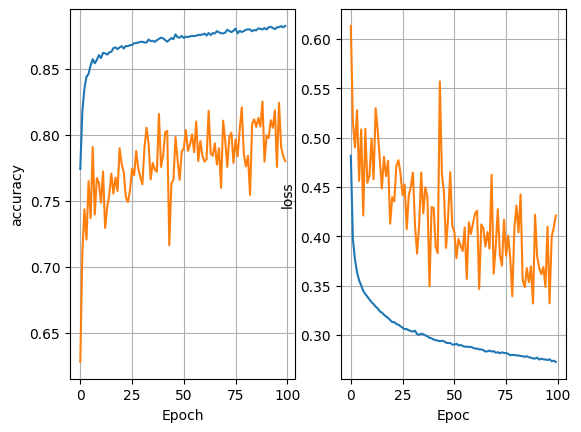

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8788 - loss: 0.2986
number of nodes 32, number of dropouts 0, learning rate value 0.001, batch_size 128
Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7491 - loss: 0.5449 - val_accuracy: 0.5983 - val_loss: 0.6667
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8038 - loss: 0.4197 - val_accuracy: 0.6378 - val_loss: 0.6243
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8201 - loss: 0.3960 - val_accuracy: 0.6398 - val_loss: 0.6251
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8319 - loss: 0.3790 - val_accuracy: 0.6836 - val_loss: 0.5724
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8416 - loss: 0.3665 - val_accuracy: 0.7325 - val_loss: 0.5142
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8470 - loss: 0.3585 - val_accuracy: 0.7174 - val_loss: 0.5443
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8507 - loss: 0

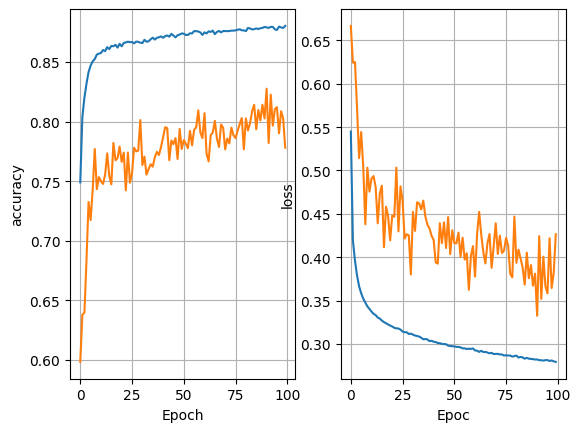

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8775 - loss: 0.3005
number of nodes 32, number of dropouts 0.2, learning rate value 0.01, batch_size 32
Epoch 1/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8127 - loss: 0.4123 - val_accuracy: 0.6954 - val_loss: 0.5689
Epoch 2/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8426 - loss: 0.3684 - val_accuracy: 0.6823 - val_loss: 0.6216
Epoch 3/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8470 - loss: 0.3567 - val_accuracy: 0.7649 - val_loss: 0.4352
Epoch 4/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8476 - loss: 0.3543 - val_accuracy: 0.7160 - val_loss: 0.5249
Epoch 5/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8476 - loss: 0.3449 - val_accuracy: 0.6401 - val_loss: 0.6535
Epoch 6/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8509 - loss: 0.3447 - val_accuracy: 0.7501 - val_loss: 0.4425
Epoch 7/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.

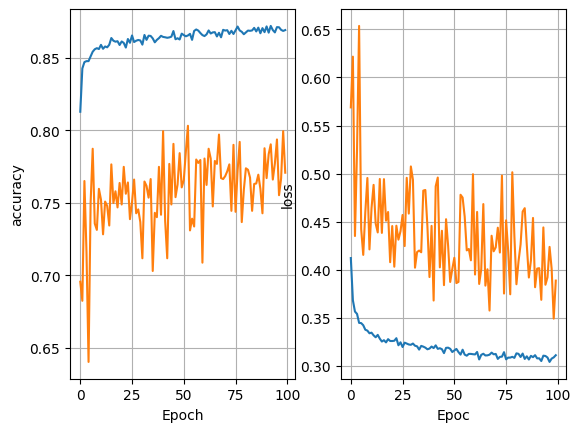

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8762 - loss: 0.3042
number of nodes 32, number of dropouts 0.2, learning rate value 0.01, batch_size 64
Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8040 - loss: 0.4259 - val_accuracy: 0.7066 - val_loss: 0.4893
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8449 - loss: 0.3670 - val_accuracy: 0.6880 - val_loss: 0.5983
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8507 - loss: 0.3552 - val_accuracy: 0.7558 - val_loss: 0.4416
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8517 - loss: 0.3538 - val_accuracy: 0.7410 - val_loss: 0.4527
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8527 - loss: 0.3479 - val_accuracy: 0.7336 - val_loss: 0.4520
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8538 - loss: 0.3408 - val_accuracy: 0.7639 - val_loss: 0.4343
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.

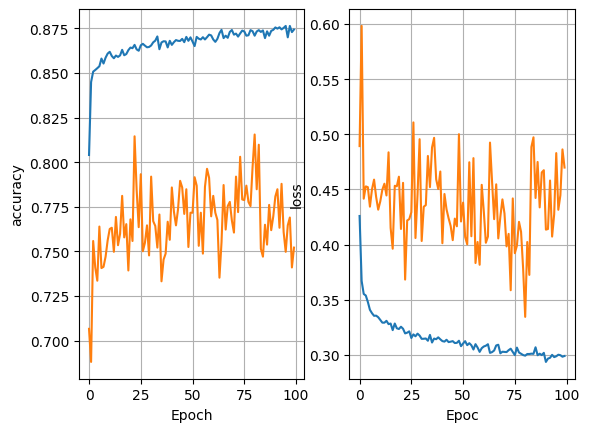

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8804 - loss: 0.2942
number of nodes 32, number of dropouts 0.2, learning rate value 0.01, batch_size 128
Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7942 - loss: 0.4381 - val_accuracy: 0.6796 - val_loss: 0.6443
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8322 - loss: 0.3824 - val_accuracy: 0.7474 - val_loss: 0.4715
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8410 - loss: 0.3646 - val_accuracy: 0.7197 - val_loss: 0.5235
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8491 - loss: 0.3509 - val_accuracy: 0.7170 - val_loss: 0.5252
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8542 - loss: 0.3458 - val_accuracy: 0.7467 - val_loss: 0.4502
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8546 - loss: 0.3406 - val_accuracy: 0.7922 - val_loss: 0.4007
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8560 - loss: 

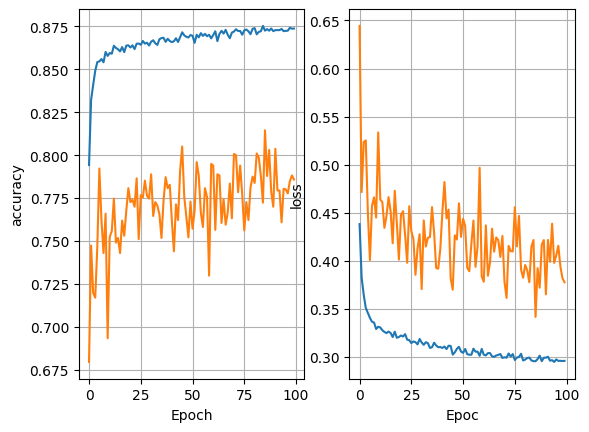

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8772 - loss: 0.3058
number of nodes 32, number of dropouts 0.2, learning rate value 0.005, batch_size 32
Epoch 1/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8045 - loss: 0.4293 - val_accuracy: 0.7285 - val_loss: 0.5120
Epoch 2/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8349 - loss: 0.3773 - val_accuracy: 0.7359 - val_loss: 0.5025
Epoch 3/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8429 - loss: 0.3668 - val_accuracy: 0.7518 - val_loss: 0.4729
Epoch 4/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8466 - loss: 0.3555 - val_accuracy: 0.7278 - val_loss: 0.4872
Epoch 5/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8499 - loss: 0.3494 - val_accuracy: 0.7595 - val_loss: 0.4386
Epoch 6/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8513 - loss: 0.3468 - val_accuracy: 0.7447 - val_loss: 0.4644
Epoch 7/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0

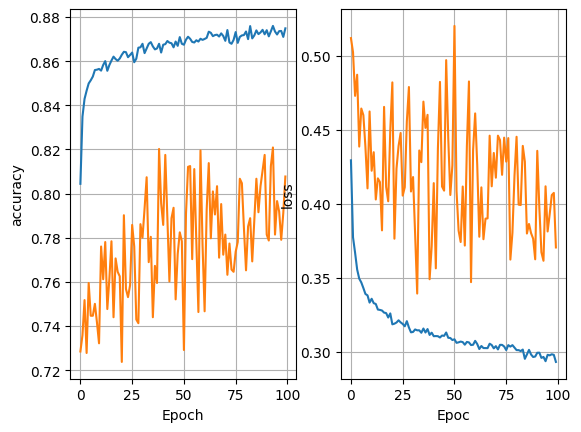

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8762 - loss: 0.3011
number of nodes 32, number of dropouts 0.2, learning rate value 0.005, batch_size 64
Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8007 - loss: 0.4375 - val_accuracy: 0.7231 - val_loss: 0.5322
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8361 - loss: 0.3798 - val_accuracy: 0.7545 - val_loss: 0.4818
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8448 - loss: 0.3637 - val_accuracy: 0.7609 - val_loss: 0.4478
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8491 - loss: 0.3539 - val_accuracy: 0.7680 - val_loss: 0.4413
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8506 - loss: 0.3485 - val_accuracy: 0.7059 - val_loss: 0.5053
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8517 - loss: 0.3446 - val_accuracy: 0.7798 - val_loss: 0.3836
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0

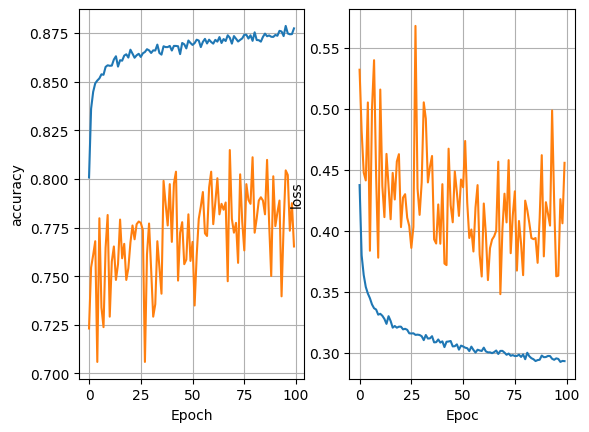

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8791 - loss: 0.2950
number of nodes 32, number of dropouts 0.2, learning rate value 0.005, batch_size 128
Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7881 - loss: 0.4539 - val_accuracy: 0.6843 - val_loss: 0.5676
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8294 - loss: 0.3953 - val_accuracy: 0.6954 - val_loss: 0.5611
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8386 - loss: 0.3761 - val_accuracy: 0.7386 - val_loss: 0.5152
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8464 - loss: 0.3634 - val_accuracy: 0.7346 - val_loss: 0.5077
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8475 - loss: 0.3602 - val_accuracy: 0.7012 - val_loss: 0.5712
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8514 - loss: 0.3515 - val_accuracy: 0.7245 - val_loss: 0.5032
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8513 - loss:

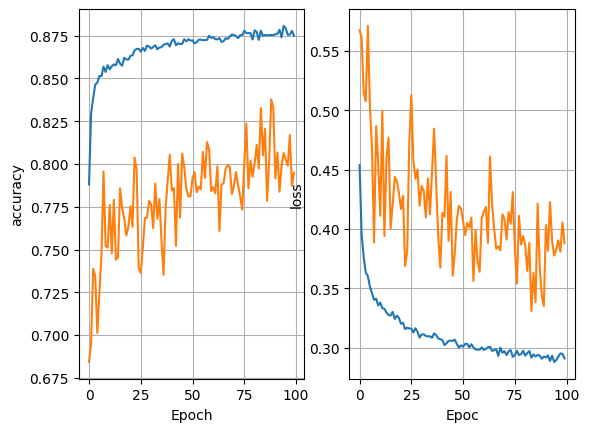

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8870 - loss: 0.2899
number of nodes 32, number of dropouts 0.2, learning rate value 0.001, batch_size 32
Epoch 1/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7705 - loss: 0.4837 - val_accuracy: 0.6519 - val_loss: 0.5763
Epoch 2/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8133 - loss: 0.4112 - val_accuracy: 0.6644 - val_loss: 0.6025
Epoch 3/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8271 - loss: 0.3946 - val_accuracy: 0.7103 - val_loss: 0.5194
Epoch 4/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8311 - loss: 0.3821 - val_accuracy: 0.7346 - val_loss: 0.5000
Epoch 5/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8390 - loss: 0.3690 - val_accuracy: 0.7110 - val_loss: 0.5352
Epoch 6/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8411 - loss: 0.3652 - val_accuracy: 0.7322 - val_loss: 0.5132
Epoch 7/100
371/371 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0

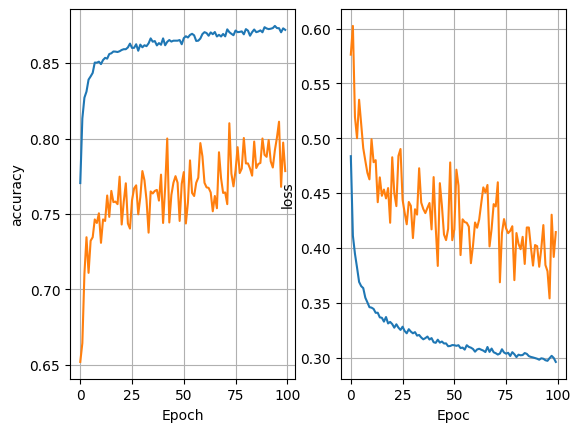

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8791 - loss: 0.2899
number of nodes 32, number of dropouts 0.2, learning rate value 0.001, batch_size 64
Epoch 1/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7516 - loss: 0.5224 - val_accuracy: 0.6132 - val_loss: 0.6697
Epoch 2/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8012 - loss: 0.4236 - val_accuracy: 0.6503 - val_loss: 0.6045
Epoch 3/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8123 - loss: 0.4137 - val_accuracy: 0.6712 - val_loss: 0.5751
Epoch 4/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8188 - loss: 0.3995 - val_accuracy: 0.6654 - val_loss: 0.5944
Epoch 5/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8253 - loss: 0.3905 - val_accuracy: 0.6992 - val_loss: 0.5393
Epoch 6/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8302 - loss: 0.3826 - val_accuracy: 0.7218 - val_loss: 0.5089
Epoch 7/100
186/186 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0

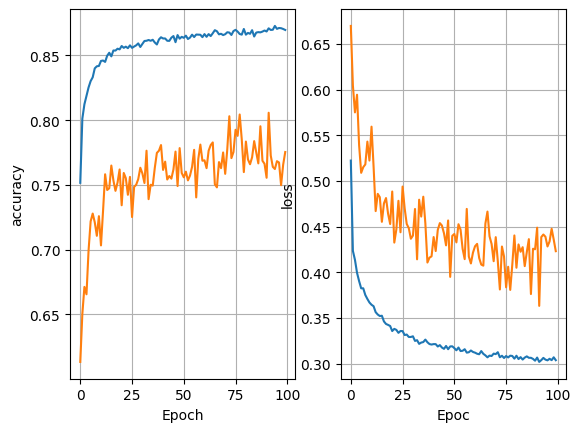

119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8793 - loss: 0.2904
number of nodes 32, number of dropouts 0.2, learning rate value 0.001, batch_size 128
Epoch 1/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.7373 - loss: 0.5477 - val_accuracy: 0.6216 - val_loss: 0.6528
Epoch 2/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7869 - loss: 0.4524 - val_accuracy: 0.6398 - val_loss: 0.6257
Epoch 3/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8022 - loss: 0.4264 - val_accuracy: 0.6681 - val_loss: 0.5863
Epoch 4/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8130 - loss: 0.4131 - val_accuracy: 0.6391 - val_loss: 0.6190
Epoch 5/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8173 - loss: 0.4057 - val_accuracy: 0.6941 - val_loss: 0.5578
Epoch 6/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8222 - loss: 0.3973 - val_accuracy: 0.6745 - val_loss: 0.5956
Epoch 7/100
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8255 - loss:

KeyboardInterrupt: 

In [28]:
least_loss = float('inf')
least_loss_model = None
epochs =100
for num_nodes in [16,32,64]:
  for dropout_prob in [0,0.2]:
    for lr in [0.01,0.005,0.001]:
      for batch_size in [32,64,128]:
        print("number of nodes {0}, number of dropouts {1}, learning rate value {2}, batch_size {3}".format(num_nodes, dropout_prob, lr, batch_size))
        model,history = train_nn_model(x_train,y_train,num_nodes, dropout_prob,lr,batch_size,epochs)
        plot_history(history)
        val_loss, val_accuracy= model.evaluate(x_valid,y_valid)
        if val_loss < least_loss:
          least_loss = val_loss
          least_loss_model = model